# Aula 08 — Assistente Multimodal: orquestração de pipelines de IA

**Disciplina: Engenharia de Machine Learning — FIAP PosTech**

---

## 🎯 Objetivo da aula

Nesta aula vamos entender, na prática, como um sistema de IA **multimodal** (que combina voz e imagem) é montado como um **pipeline de vários modelos** e por que a **orquestração** — em especial a **execução paralela** de etapas independentes — é essencial para manter a **latência baixa**.

Usaremos como exemplo o caso de um **assistente virtual multimodal**. Ao final, você será capaz de:

1. Entender o problema de latência ponta a ponta em um pipeline com vários modelos.
2. Explicar de forma simples o que são **pipeline de inferência**, **orquestração**, **microsserviços** e **execução paralela**.
3. Medir na prática o **tempo total** e a **latência** de um pipeline multimodal.
4. Comparar a execução **sequencial** com a execução **orquestrada (paralela)**.
5. Avaliar se a resposta cabe na meta de **poucos segundos** (< 1 s).
6. Discutir ferramentas e práticas reais de **orquestração e MLOps** (Airflow, Kubeflow, Triton, autoscaling) e seus trade-offs.

## ✅ Pré-requisitos

Antes de executar este notebook, garanta o seguinte:

### 1. Software necessário

| Item | Versão mínima | Observação |
|---|---|---|
| **Python** | 3.10+ | Verifique com `python --version` |
| **Jupyter** | 1.0+ | Para abrir e executar o notebook |
| **NumPy** | 1.24+ | Geração de ruído e estatísticas |
| **Pandas** | 2.0+ | Tabela comparativa |
| **Matplotlib** | 3.7+ | Visualizações |

Este notebook é **leve e autocontido**: usa apenas `numpy`, `pandas` e `matplotlib` (e o módulo padrão `concurrent.futures`). **Não requer GPU**, internet ou datasets externos — roda em qualquer ambiente local simples.

### 2. Instalação das dependências

**Opção A — no terminal (recomendado):**

```bash
# a partir da pasta 08_escalabilidade_orquestracao_multimodal
pip install -r requirements.txt

# ou, o mínimo para este notebook:
pip install numpy pandas matplotlib jupyter
```

**Opção B — direto no notebook:** execute a célula de instalação logo abaixo (descomente a linha `%pip install ...`).

### 3. Selecionar o kernel correto

No canto superior direito do notebook, clique em **"Select Kernel"** e escolha o interpretador Python onde as dependências foram instaladas. Se aparecer `ModuleNotFoundError`, quase sempre significa que o kernel selecionado não é o mesmo ambiente da instalação — selecione o kernel certo (ou rode a célula de instalação abaixo) e execute novamente.

In [1]:
# (Opcional) Instalar as dependencias diretamente no kernel atual.
# Descomente a linha abaixo caso veja "ModuleNotFoundError" ao rodar as proximas celulas.
%pip install numpy pandas matplotlib

# Verificacao rapida do ambiente
import sys
print("Python:", sys.version.split()[0])
try:
    import numpy, pandas, matplotlib
    print("numpy:", numpy.__version__)
    print("pandas:", pandas.__version__)
    print("matplotlib:", matplotlib.__version__)
    print("Dependencias OK. Pode seguir para a proxima celula.")
except ModuleNotFoundError as e:
    print("Faltando:", e.name)
    print("=> Descomente a linha '%pip install numpy pandas matplotlib' acima e rode esta celula novamente.")

Note: you may need to restart the kernel to use updated packages.
Python: 3.13.14
numpy: 2.5.0
pandas: 3.0.3
matplotlib: 3.11.0
Dependencias OK. Pode seguir para a proxima celula.


## 1. Introdução: o assistente virtual multimodal

Imagine um **assistente virtual multimodal**. O usuário faz uma **pergunta por voz** e **anexa uma imagem** para dar mais contexto — algo cada vez mais comum em assistentes modernos.

Para responder, o sistema executa uma **sequência de etapas**, cada uma com um modelo diferente:

1. **ASR (Automatic Speech Recognition):** converte o áudio da pergunta em **texto**.
2. **NLP:** analisa o texto transcrito para extrair a **intenção** e o significado.
3. **Visão computacional:** processa a **imagem** (ex.: identifica objetos ou texto nela).
4. **Lógica de negócio:** combina os resultados do áudio e da imagem e gera uma **resposta em texto**.
5. **TTS (Text-to-Speech):** converte a resposta em **áudio** para "falar" com o usuário.

```
🎤 Voz ─► [ASR] ─► texto ─► [NLP] ─┐
                                    ├─► [Lógica] ─► resposta ─► [TTS] ─► 🔊 Fala
🖼️ Imagem ──────────► [Visão] ─────┘
```

### O desafio

- **Múltiplos modelos e etapas** precisam ser coordenados de forma eficiente.
- Algumas etapas dependem de outras (NLP só roda **depois** do ASR), mas outras são **independentes** (a Visão pode rodar **ao mesmo tempo** que ASR+NLP).
- A **latência ponta a ponta** precisa ser baixa: tudo deve ocorrer em **poucos segundos** (meta: **< 1 s**) para a experiência ser fluida.
- Manter tantos modelos no ar é **complexo**: exige orquestração distribuída e práticas de **MLOps**.

> 🧩 A pergunta central da aula é: **como coordenar todos esses modelos para responder ao usuário no menor tempo possível?**

## 2. Conceitos principais

Antes do hands-on, alguns conceitos simples que amarram toda a aula. A ideia é entender **como orquestrar** os modelos — não decorar teoria.

### 🔗 Pipeline de inferência

É a **sequência de etapas** que os dados percorrem até virar a resposta final. No nosso caso: ASR → NLP → (Visão em paralelo) → Lógica → TTS. Cada etapa é um **modelo** ou um bloco de processamento.

### 🧱 Microsserviços de ML

Cada modelo é implantado como um **serviço separado** (microsserviço), que se comunica com os outros por **APIs, mensagens ou filas**. Isso permite **escalar cada etapa de forma independente** e **atualizar um modelo** sem reescrever o sistema todo.

### 🎯 Orquestração

É a **coordenação central** do fluxo entre os modelos: garantir que a próxima etapa só comece quando os **dados de entrada estiverem prontos** e disparar em **paralelo** as etapas que são **independentes**. Ferramentas comuns: **Apache Airflow** (DAGs que agendam tarefas) e **Kubeflow Pipelines** (fluxos de ML em Kubernetes).

### ⚡ Execução paralela

Rodar ao mesmo tempo as etapas que **não dependem uma da outra**. No assistente, o ramo de **áudio (ASR+NLP)** e o ramo de **imagem (Visão)** são independentes — podem rodar em paralelo, e o tempo total passa a ser o do **ramo mais lento**, não a soma dos dois.

### 🖥️ Servidores de inferência

Softwares que servem modelos em produção via API: **TensorFlow Serving**, **TorchServe**, **BentoML**, **NVIDIA Triton**. Cuidam de batching, múltiplas instâncias e roteamento.

### 🔧 MLOps (operação de ML)

Conjunto de práticas para manter o sistema saudável em produção:

- **Monitoramento e alertas:** acompanhar latência, acurácia e recursos; detectar falhas cedo.
- **Autoscaling e alta disponibilidade:** ajustar instâncias conforme a carga; se um serviço cai, outro assume.
- **CI/CD e versionamento:** atualizar modelos sem derrubar o serviço; versionar dados/modelos para reprodutibilidade.
- **Feedback loop e A/B testing:** usar dados reais para melhorar e validar novos modelos.

### ☁️ Edge x Cloud

- **Borda (edge):** rodar perto do usuário → **latência mínima** e menos uso de rede.
- **Nuvem (cloud):** poder de processamento **escalável**.
- **Híbrido:** decidir **onde roda cada componente**, considerando também **privacidade** dos dados.

## 3. Hands-on prático

Vamos focar em **um** conceito no hands-on: a **execução paralela orquestrada**. Vamos **simular** as 5 etapas do assistente e medir o tempo total em dois cenários:

- **Cenário A — Sequencial:** roda uma etapa após a outra (ASR → NLP → Visão → Lógica → TTS).
- **Cenário B — Orquestrado (paralelo):** roda o ramo de **áudio (ASR+NLP)** e o ramo de **imagem (Visão)** ao mesmo tempo; quando ambos terminam, executa Lógica e TTS.

Em vez de rodar modelos reais (que exigiriam GPU e bibliotecas pesadas), simulamos o **tempo de cada etapa** com `time.sleep()`. O foco fica onde importa: **ver como a orquestração paralela reduz a latência ponta a ponta**.

Primeiro, os imports e os tempos simulados de cada etapa.

In [2]:
# ------------------------------------------------------------------
# IMPORTS - enxutos para manter o notebook leve e sem GPU
# ------------------------------------------------------------------
import time                                   # medir o tempo (latencia)
import numpy as np                            # estatisticas / jitter
import pandas as pd                           # tabela comparativa
import matplotlib.pyplot as plt               # visualizar os resultados
from concurrent.futures import ThreadPoolExecutor  # rodar etapas em paralelo

# Semente fixa -> resultados reproduziveis (todos veem numeros parecidos).
np.random.seed(42)

# ------------------------------------------------------------------
# TEMPOS SIMULADOS DE CADA ETAPA (em milissegundos) - numeros didaticos
# ------------------------------------------------------------------
# Cada modelo do pipeline leva um tempo tipico para processar sua parte.
TEMPOS_MS = {
    "ASR":    250,   # transcrever a fala em texto
    "NLP":    200,   # interpretar o texto (intencao)
    "Visao":  300,   # analisar a imagem anexada
    "Logica": 100,   # combinar resultados e montar a resposta
    "TTS":    150,   # converter a resposta em audio
}

# Meta de negocio: resposta fluida em poucos segundos (aqui, menos de 1 s).
META_MS = 1000

print("Tempos por etapa (ms):", TEMPOS_MS)
print(f"Meta de resposta fluida: < {META_MS} ms (1 s)")

Tempos por etapa (ms): {'ASR': 250, 'NLP': 200, 'Visao': 300, 'Logica': 100, 'TTS': 150}
Meta de resposta fluida: < 1000 ms (1 s)


In [3]:
# ==================================================================
# FUNCAO AUXILIAR - simula UMA etapa do pipeline
# ==================================================================
# OBJETIVO: imitar o tempo que um modelo leva para processar sua etapa.
#
# POR QUE SIMULAR com time.sleep()?
#   - Rodar ASR, NLP, Visao e TTS de verdade exigiria GPU, modelos treinados
#     e audio/imagem reais. Nesta aula o foco NAO e a qualidade da resposta,
#     e sim ENTENDER como orquestrar as etapas para reduzir a latencia.
#   - Entao "dormir" X ms finge que o modelo levou X ms para processar.


def executar_etapa(nome, jitter_ms=10.0):
    """Simula a execucao de uma etapa e devolve o tempo real gasto (ms).

    Parametros
    ----------
    nome      : chave da etapa em TEMPOS_MS (ex.: 'ASR').
    jitter_ms : variacao aleatoria do tempo (realismo).
    """
    # Tempo medio da etapa + uma pequena variacao aleatoria (jitter).
    base = TEMPOS_MS[nome]
    atraso_ms = max(1.0, base + np.random.normal(0, jitter_ms))

    t0 = time.perf_counter()
    time.sleep(atraso_ms / 1000.0)   # "processa" a etapa (÷1000: ms -> s)
    t1 = time.perf_counter()

    return (t1 - t0) * 1000.0         # tempo real medido, em ms


print("Funcao 'executar_etapa' pronta para uso.")

Funcao 'executar_etapa' pronta para uso.


### Cenário A — Pipeline sequencial

Aqui rodamos **uma etapa após a outra**, sem paralelismo. O tempo total é a **soma** de todas as etapas — inclusive das que poderiam rodar ao mesmo tempo.

In [4]:
# Cenario A - execucao SEQUENCIAL: ASR -> NLP -> Visao -> Logica -> TTS
inicio = time.perf_counter()

t_asr    = executar_etapa("ASR")      # 1) transcreve a fala
t_nlp    = executar_etapa("NLP")      # 2) interpreta o texto
t_visao  = executar_etapa("Visao")    # 3) analisa a imagem (aqui, em serie)
t_logica = executar_etapa("Logica")   # 4) combina resultados
t_tts    = executar_etapa("TTS")      # 5) gera o audio da resposta

tempo_seq_ms = (time.perf_counter() - inicio) * 1000.0

print("=== Cenario A - Pipeline sequencial ===")
print(f"ASR: {t_asr:.0f} ms | NLP: {t_nlp:.0f} ms | Visao: {t_visao:.0f} ms | Logica: {t_logica:.0f} ms | TTS: {t_tts:.0f} ms")
print(f"Tempo total (ponta a ponta): {tempo_seq_ms:.0f} ms")

atende_seq = tempo_seq_ms < META_MS
print(f"Atende a meta (< {META_MS} ms)? -> {'SIM' if atende_seq else 'NAO'}")

=== Cenario A - Pipeline sequencial ===
ASR: 255 ms | NLP: 199 ms | Visao: 307 ms | Logica: 116 ms | TTS: 148 ms
Tempo total (ponta a ponta): 1027 ms
Atende a meta (< 1000 ms)? -> NAO


Somando todas as etapas em série, o tempo total passa de **1 segundo** — acima da meta. Note que **ASR+NLP** (áudio) e **Visão** (imagem) foram executados um após o outro, mesmo sendo **independentes**. É exatamente aí que a orquestração paralela vai ajudar.

### Cenário B — Pipeline orquestrado (execução paralela)

Agora **orquestramos** o pipeline: o ramo de **áudio (ASR → NLP)** e o ramo de **imagem (Visão)** rodam **ao mesmo tempo**. Só quando **ambos** terminam é que executamos a **Lógica** (que depende dos dois) e, por fim, o **TTS**.

In [5]:
# Cenario B - execucao ORQUESTRADA (paralela)
# Ramo de audio: ASR seguido de NLP (dependentes entre si).
def ramo_audio():
    """Executa ASR e depois NLP (o NLP depende do texto do ASR)."""
    executar_etapa("ASR")
    executar_etapa("NLP")

# Ramo de imagem: apenas Visao (independente do ramo de audio).
def ramo_imagem():
    """Executa a analise da imagem."""
    executar_etapa("Visao")

inicio = time.perf_counter()

# 1) Dispara os DOIS ramos AO MESMO TEMPO (paralelismo de etapas independentes).
#    O ThreadPoolExecutor roda as duas funcoes em threads separadas; como a
#    simulacao usa time.sleep (I/O), as threads realmente rodam em paralelo.
with ThreadPoolExecutor(max_workers=2) as executor:
    futuro_audio  = executor.submit(ramo_audio)   # ASR + NLP
    futuro_imagem = executor.submit(ramo_imagem)  # Visao
    # 2) A orquestracao ESPERA os dois ramos terminarem (dependencia da Logica).
    futuro_audio.result()
    futuro_imagem.result()

# 3) Agora que audio e imagem estao prontos, combina e gera o audio final.
executar_etapa("Logica")   # depende de audio + imagem
executar_etapa("TTS")      # gera a fala da resposta

tempo_par_ms = (time.perf_counter() - inicio) * 1000.0

print("=== Cenario B - Pipeline orquestrado (paralelo) ===")
print("Ramo audio (ASR+NLP) e ramo imagem (Visao) rodaram EM PARALELO.")
print(f"Tempo total (ponta a ponta): {tempo_par_ms:.0f} ms")

atende_par = tempo_par_ms < META_MS
print(f"Atende a meta (< {META_MS} ms)? -> {'SIM' if atende_par else 'NAO'}")

# Quanto a orquestracao paralela economizou em relacao ao sequencial?
ganho = tempo_seq_ms / tempo_par_ms
print(f"\nA orquestracao paralela ficou ~{ganho:.2f}x mais rapida que a sequencial.")

=== Cenario B - Pipeline orquestrado (paralelo) ===
Ramo audio (ASR+NLP) e ramo imagem (Visao) rodaram EM PARALELO.
Tempo total (ponta a ponta): 711 ms
Atende a meta (< 1000 ms)? -> SIM

A orquestracao paralela ficou ~1.44x mais rapida que a sequencial.


## 4. Comparação dos resultados

Vamos consolidar os dois cenários em uma **tabela** e, em seguida, em um **gráfico** para visualizar a diferença de tempo total.

No paralelo, o tempo do trecho concorrente é o do **ramo mais lento**: `ASR+NLP` (~450 ms) vs `Visão` (~300 ms) → vale ~450 ms, em vez dos ~750 ms somados no sequencial.

In [6]:
# Numero de etapas do pipeline (as mesmas nos dois cenarios).
n_etapas = len(TEMPOS_MS)

# Tabela comparativa dos dois cenarios
tabela = pd.DataFrame([
    {
        "Cenario": "A - Sequencial",
        "Etapas": n_etapas,
        "Latencia total (ms)": round(tempo_seq_ms),
        "Latencia media/etapa (ms)": round(tempo_seq_ms / n_etapas),
        "Atende < 1 s?": "Sim" if tempo_seq_ms < META_MS else "Nao",
    },
    {
        "Cenario": "B - Orquestrado (paralelo)",
        "Etapas": n_etapas,
        "Latencia total (ms)": round(tempo_par_ms),
        "Latencia media/etapa (ms)": round(tempo_par_ms / n_etapas),
        "Atende < 1 s?": "Sim" if tempo_par_ms < META_MS else "Nao",
    },
])
tabela

,Cenario,Etapas,Latencia total (ms),Latencia media/etapa (ms),Atende < 1 s?
0,A - Sequencial,5,1027,205,Nao
1,B - Orquestrado (paralelo),5,711,142,Sim


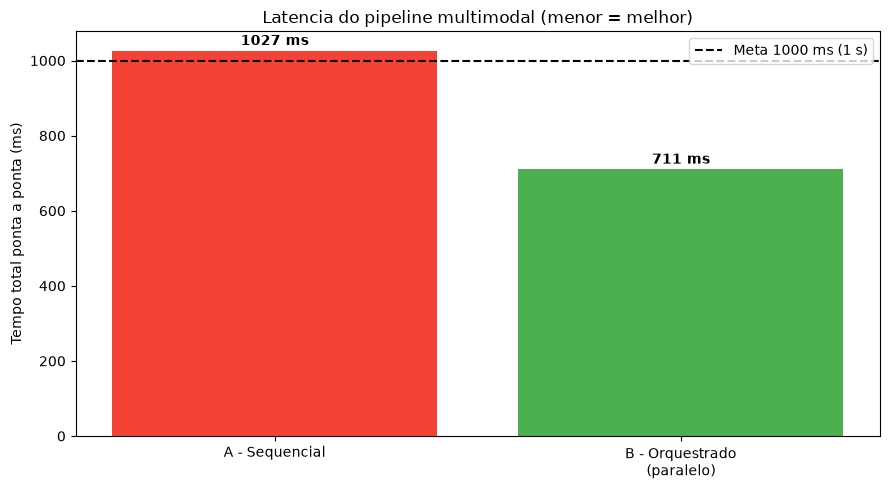

In [7]:
# Grafico comparativo: tempo total ponta a ponta por cenario
fig, ax = plt.subplots(figsize=(9, 5))

cenarios = ["A - Sequencial", "B - Orquestrado\n(paralelo)"]
tempos = [tempo_seq_ms, tempo_par_ms]
cores = ["#F44336", "#4CAF50"]  # vermelho = ruim, verde = bom

ax.bar(cenarios, tempos, color=cores)
ax.axhline(META_MS, color="black", linestyle="--", label=f"Meta {META_MS} ms (1 s)")
ax.set_ylabel("Tempo total ponta a ponta (ms)")
ax.set_title("Latencia do pipeline multimodal (menor = melhor)")
ax.legend()
for i, v in enumerate(tempos):
    ax.text(i, v + 15, f"{v:.0f} ms", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

## 5. Discussão técnica: como escalar e operar de verdade?

Na simulação apenas **paralelizamos etapas independentes**. No mundo real, um assistente multimodal em produção combina várias técnicas de **orquestração** e **MLOps**. Você **não precisa implementar todas** — basta entender como cada uma ajudaria o assistente:

| Técnica / Ferramenta | Ideia central | Como ajuda o assistente |
|---|---|---|
| **Pipeline de ML** | encadear etapas de processamento | organiza ASR → NLP / Visão → Lógica → TTS |
| **Orquestração (Airflow / Kubeflow)** | coordenar dependências e paralelismo | dispara ramos independentes juntos |
| **Microsserviços de inferência** | cada modelo como serviço via API | escalar/atualizar um modelo isoladamente |
| **Servidores de modelo (Triton, BentoML)** | servir modelos em produção | batching, múltiplas instâncias |
| **Balanceador de carga + autoscaling** | distribuir carga e ajustar instâncias | aguenta picos (ex.: evento ao vivo) |
| **Monitoramento e alertas** | acompanhar latência/erros; SLOs | detecta lentidão/falha cedo |
| **CI/CD + versionamento** | atualizar modelos sem downtime | troca o TTS por um melhor sem reescrever tudo |
| **Feedback loop + A/B testing** | usar dados reais e testar versões | melhora contínua da qualidade |
| **Edge x Cloud (híbrido)** | decidir onde roda cada parte | menor latência e privacidade |

> 💡 No caso real descrito, a combinação de **otimização de cada modelo + orquestração que paraleliza tarefas independentes + microsserviços com autoscaling + MLOps ativo** levou a resposta a **menos de 1 segundo em média**, com o sistema **escalável**, **modular** e **monitorado**.

### ⚖️ Trade-offs entre modularidade, custo e latência

Dividir tudo em microsserviços traz **modularidade** (fácil atualizar), mas adiciona **latência de rede** entre serviços e **complexidade operacional**. Rodar na **nuvem** escala, mas custa; rodar na **borda** reduz latência, mas limita recursos. O segredo é equilibrar **modularidade**, **custo** e **latência** conforme a necessidade do produto.

## 6. Conclusão

Respondendo às perguntas centrais da aula:

**1. A execução sequencial atende à meta de resposta fluida (< 1 s)?**
❌ **Não (ou no limite).** Somando todas as etapas em série, o tempo total passa de ~1 s, porque etapas independentes (áudio e imagem) esperam uma à outra sem necessidade.

**2. A execução paralela melhora o tempo total?**
✅ **Sim.** Ao rodar o ramo de **áudio (ASR+NLP)** e o ramo de **imagem (Visão)** ao mesmo tempo, o trecho concorrente passa a custar o do ramo **mais lento** (não a soma), e o tempo ponta a ponta cai para **menos de 1 s**.

**3. A orquestração ajuda a manter o sistema modular?**
✅ **Sim.** Com cada modelo como um **microsserviço**, é possível **atualizar ou trocar** um componente (ex.: um TTS mais natural) sem reescrever o sistema, bastando respeitar a interface de comunicação.

**4. O uso de MLOps melhora operação e manutenção?**
✅ **Sim.** Monitoramento, alertas, autoscaling, CI/CD e feedback loop mantêm o sistema **estável**, **escalável** e em **melhoria contínua** — problemas são detectados cedo e os modelos são re-treinados com dados atualizados.

**5. Quais trade-offs existem entre escalabilidade, complexidade e latência?**
Mais serviços e paralelismo = mais **escalabilidade e modularidade**, mas também mais **latência de rede** e **complexidade operacional**. Ferramentas de orquestração e MLOps tornam esse equilíbrio viável.

### 📌 Principais aprendizados

1. Aplicações **multimodais** são **pipelines de vários modelos** que precisam ser coordenados.
2. **Paralelizar etapas independentes** reduz a latência ponta a ponta.
3. **Microsserviços** deixam o sistema modular e fácil de evoluir.
4. **Orquestradores** (Airflow, Kubeflow) cuidam de dependências e paralelismo.
5. **MLOps** (monitoramento, autoscaling, CI/CD, feedback) mantém qualidade e disponibilidade ao longo do tempo.

### 🚀 Próximos passos sugeridos

- Variar os tempos em `TEMPOS_MS` e ver quando o paralelismo compensa mais.
- Adicionar uma etapa extra (ex.: um segundo modelo de visão) e reorganizar os ramos.
- Explorar, em um próximo módulo, uma orquestração real com **Airflow** ou **Kubeflow Pipelines**.

---

*Material da Aula 08 — Engenharia de Machine Learning — FIAP PosTech.*